# TA-06 – Eksplorasi Mendalam Algoritma Random Forest
**Studi kasus:** Prediksi *Customer Churn* pelanggan telekomunikasi
**Dataset (Kaggle):** [Telco Customer Churn – blastchar](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (`WA_Fn-UseC_-Telco-Customer-Churn.csv`)
**Target:** `Churn` (Yes = pelanggan berhenti berlangganan, No = bertahan)

Dataset diunduh otomatis dari Kaggle saat sel pemuatan data dijalankan (butuh internet; paket `kagglehub`).

## 1. Persiapan Data & Preprocessing

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
os.makedirs("model", exist_ok=True)
os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid")

In [2]:
# Load data
# Dataset diunduh OTOMATIS dari Kaggle saat notebook dijalankan (tidak perlu unduh manual).
import glob, shutil, urllib.request
os.makedirs("data", exist_ok=True)
DATA_PATH = os.environ.get("DATA_PATH", "data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

if not os.path.exists(DATA_PATH):
    try:                                   # 1) Kaggle via kagglehub
        import kagglehub
        folder = kagglehub.dataset_download("blastchar/telco-customer-churn")
        shutil.copy(glob.glob(os.path.join(folder, "*.csv"))[0], DATA_PATH)
        print("Dataset diunduh dari Kaggle (kagglehub).")
    except Exception as e:                 # 2) cadangan: salinan publik dataset yang sama (IBM)
        print("kagglehub gagal:", type(e).__name__, "-> memakai salinan publik.")
        url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
        urllib.request.urlretrieve(url, DATA_PATH)
else:
    print("Dataset sudah ada, tidak diunduh ulang.")

df = pd.read_csv(DATA_PATH)
print("Ukuran data:", df.shape)
df.head()

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 172k/172k [00:00<00:00, 313kB/s]

Extracting files...
Dataset diunduh dari Kaggle (kagglehub).
Ukuran data: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Cek tipe data, nilai hilang, dan perbaikan kolom TotalCharges (berisi spasi kosong untuk pelanggan baru)
df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values per kolom:\n", df.isnull().sum()[df.isnull().sum() > 0])
df["TotalCharges"] = df["TotalCharges"].fillna(0)   # tenure = 0 -> belum ada tagihan
df.info()

Missing values per kolom:
 TotalCharges    11
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-nul

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46 %
Yes    26.54 %
Name: count, dtype: object


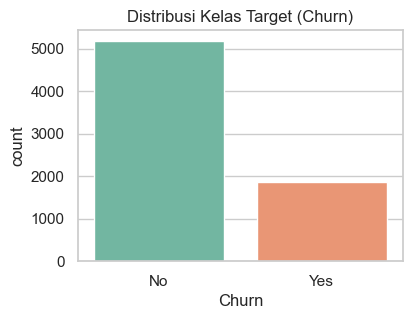

In [4]:
# Analisis awal: ketidakseimbangan kelas pada target
counts = df["Churn"].value_counts()
print(counts)
print((counts / len(df) * 100).round(2).astype(str) + " %")
plt.figure(figsize=(4.2, 3.0))
ax = sns.countplot(data=df, x="Churn", palette="Set2")
ax.set_title("Distribusi Kelas Target (Churn)")
plt.savefig("figures/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# Encoding: target -> 0/1, fitur kategori -> One-Hot Encoding
y = (df["Churn"] == "Yes").astype(int)
X_raw = df.drop(columns=["Churn"])
cat_cols = X_raw.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X_raw.columns if c not in cat_cols]
print("Kolom kategori:", cat_cols)
print("Kolom numerik :", num_cols)

X = pd.get_dummies(X_raw, columns=cat_cols, drop_first=False, dtype=int)
print("Jumlah fitur setelah encoding:", X.shape[1])

Kolom kategori: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Kolom numerik : ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Jumlah fitur setelah encoding: 45


In [6]:
# Split data: 80% training, 20% testing (stratified agar proporsi kelas terjaga)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporsi churn train/test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Train: (5634, 45) | Test: (1409, 45)
Proporsi churn train/test: 0.265 / 0.265


## 2. Modeling & Eksperimen Hyperparameter

### Skenario A – Pengaruh Jumlah Pohon (`n_estimators`)

,n_estimators,train_acc,test_acc
0,10,0.9812,0.7786
1,50,0.9977,0.7800
2,100,0.9980,0.7871
3,200,0.9980,0.7857
4,500,0.9980,0.7835


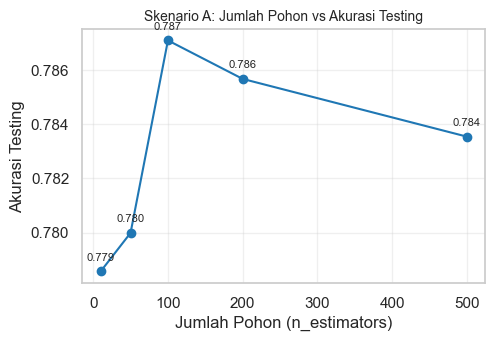

n_estimators terbaik: 100


In [7]:
n_list = [10, 50, 100, 200, 500]
res_a = []
for n in n_list:
    rf = RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train, y_train)
    res_a.append({"n_estimators": n,
                  "train_acc": accuracy_score(y_train, rf.predict(X_train)),
                  "test_acc": accuracy_score(y_test, rf.predict(X_test))})
res_a = pd.DataFrame(res_a)
display(res_a.round(4))

plt.figure(figsize=(5.2, 3.3))
plt.plot(res_a["n_estimators"], res_a["test_acc"], marker="o", color="tab:blue")
for _, r in res_a.iterrows():
    plt.annotate(f"{r.test_acc:.3f}", (r.n_estimators, r.test_acc), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.xlabel("Jumlah Pohon (n_estimators)"); plt.ylabel("Akurasi Testing")
plt.title("Skenario A: Jumlah Pohon vs Akurasi Testing", fontsize=10); plt.grid(True, alpha=.3)
plt.savefig("figures/skenario_a.png", dpi=150, bbox_inches="tight"); plt.show()

# Pilih n_estimators terbaik: akurasi testing tertinggi; bila selisih <= 0.002, pilih yang lebih kecil (lebih efisien)
best_acc = res_a["test_acc"].max()
BEST_N = int(res_a[res_a["test_acc"] >= best_acc - 0.002]["n_estimators"].min())
print("n_estimators terbaik:", BEST_N)

**Analisis Skenario A:** *(isi setelah menjalankan notebook dengan dataset asli – apakah menambah pohon terus-menerus meningkatkan akurasi secara signifikan, dan pada jumlah berapa kurva mulai mendatar.)*

### Skenario B – Pengaruh Kedalaman Pohon (`max_depth`)

,max_depth,train_acc,test_acc,gap
0,None,0.9980,0.7871,0.2110
1,3,0.7890,0.7835,0.0054
2,5,0.8016,0.7928,0.0088
3,10,0.8745,0.8006,0.0739
4,20,0.9980,0.7871,0.2110


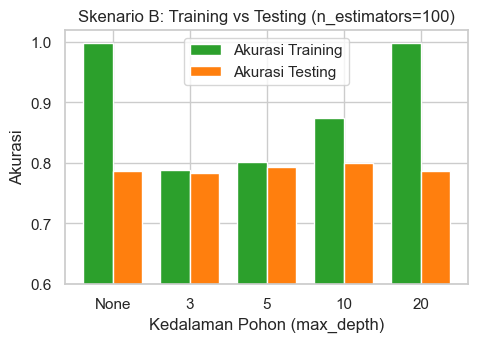

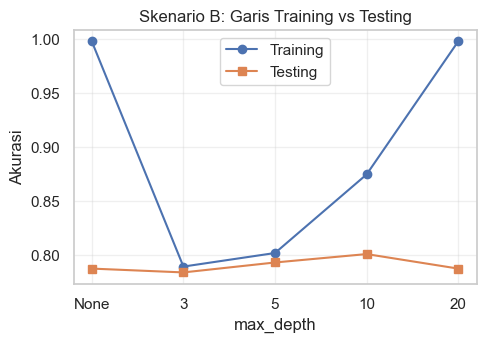

In [8]:
depth_list = [None, 3, 5, 10, 20]
res_b = []
for d in depth_list:
    rf = RandomForestClassifier(n_estimators=BEST_N, max_depth=d, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train, y_train)
    tr, te = accuracy_score(y_train, rf.predict(X_train)), accuracy_score(y_test, rf.predict(X_test))
    res_b.append({"max_depth": "None" if d is None else d, "train_acc": tr, "test_acc": te, "gap": tr - te})
res_b = pd.DataFrame(res_b)
display(res_b.round(4))

x = np.arange(len(res_b)); w = 0.38
plt.figure(figsize=(5.2, 3.3))
plt.bar(x - w/2, res_b["train_acc"], w, label="Akurasi Training", color="tab:green")
plt.bar(x + w/2, res_b["test_acc"], w, label="Akurasi Testing", color="tab:orange")
plt.xticks(x, res_b["max_depth"].astype(str)); plt.ylim(0.6, 1.02)
plt.xlabel("Kedalaman Pohon (max_depth)"); plt.ylabel("Akurasi")
plt.title(f"Skenario B: Training vs Testing (n_estimators={BEST_N})"); plt.legend()
plt.savefig("figures/skenario_b_bar.png", dpi=150, bbox_inches="tight"); plt.show()

plt.figure(figsize=(5.2, 3.3))
plt.plot(res_b["max_depth"].astype(str), res_b["train_acc"], marker="o", label="Training")
plt.plot(res_b["max_depth"].astype(str), res_b["test_acc"], marker="s", label="Testing")
plt.xlabel("max_depth"); plt.ylabel("Akurasi"); plt.title("Skenario B: Garis Training vs Testing")
plt.legend(); plt.grid(True, alpha=.3)
plt.savefig("figures/skenario_b_line.png", dpi=150, bbox_inches="tight"); plt.show()

**Analisis Skenario B:** *(isi setelah menjalankan notebook – pada `max_depth` berapa selisih Training–Testing (kolom `gap`) mulai melebar sehingga model mulai overfitting.)*

In [9]:
# Pilih max_depth terbaik: akurasi testing tertinggi dengan gap training-testing paling kecil sebagai tie-breaker
cand = res_b[res_b["test_acc"] >= res_b["test_acc"].max() - 0.002].sort_values("gap")
bd = cand.iloc[0]["max_depth"]
BEST_DEPTH = None if bd == "None" else int(bd)
print("max_depth terbaik:", BEST_DEPTH, "| n_estimators terbaik:", BEST_N)

max_depth terbaik: 10 | n_estimators terbaik: 100


## 3. Analisis Feature Importance

,Feature,Importance
0,tenure,0.1413
1,TotalCharges,0.1253
2,MonthlyCharges,0.0885
3,Contract_Month-to-month,0.0865
4,OnlineSecurity_No,0.0527
5,InternetService_Fiber optic,0.0525
6,PaymentMethod_Electronic check,0.0447
7,TechSupport_No,0.0409
8,Contract_Two year,0.0281
9,OnlineBackup_No,0.0186


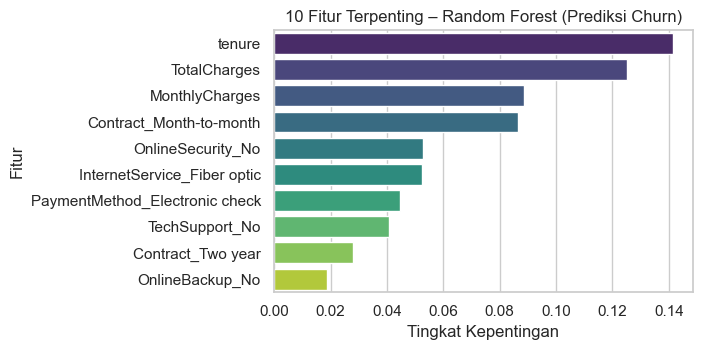

In [10]:
best_model = RandomForestClassifier(n_estimators=BEST_N, max_depth=BEST_DEPTH, random_state=RANDOM_STATE, n_jobs=-1)
best_model.fit(X_train, y_train)

imp = pd.DataFrame({"Feature": X.columns, "Importance": best_model.feature_importances_})
imp = imp.sort_values("Importance", ascending=False).reset_index(drop=True)
top10 = imp.head(10)
display(top10.round(4))

plt.figure(figsize=(5.4, 3.4))
sns.barplot(data=top10, x="Importance", y="Feature", palette="viridis")
plt.title("10 Fitur Terpenting – Random Forest (Prediksi Churn)")
plt.xlabel("Tingkat Kepentingan"); plt.ylabel("Fitur")
plt.savefig("figures/feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretasi:** *(isi setelah menjalankan notebook – jelaskan logika bisnis di balik fitur teratas, mis. `tenure`, `Contract`, `MonthlyCharges`, `TotalCharges`, `InternetService`, dan apakah sesuai dengan teori/intuisi churn pada industri telekomunikasi.)*

## 4. Evaluasi Akhir & Kesimpulan

Konfigurasi terbaik: n_estimators=100, max_depth=10
Akurasi Training: 0.8745
Akurasi Testing : 0.8006

Classification Report:
               precision    recall  f1-score   support

 Tidak Churn       0.84      0.90      0.87      1035
       Churn       0.66      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



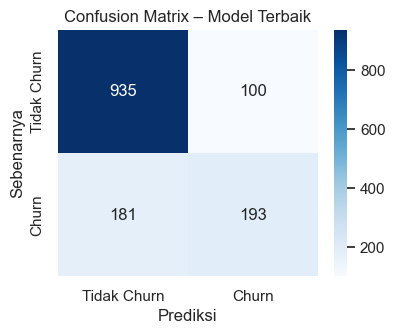

In [11]:
y_pred = best_model.predict(X_test)
print(f"Konfigurasi terbaik: n_estimators={BEST_N}, max_depth={BEST_DEPTH}")
print("Akurasi Training:", round(accuracy_score(y_train, best_model.predict(X_train)), 4))
print("Akurasi Testing :", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=["Tidak Churn", "Churn"]))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4.2, 3.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Tidak Churn", "Churn"], yticklabels=["Tidak Churn", "Churn"])
plt.xlabel("Prediksi"); plt.ylabel("Sebenarnya"); plt.title("Confusion Matrix – Model Terbaik")
plt.savefig("figures/confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Simpan Model untuk Deployment Web

In [12]:
# Simpan model + metadata form (opsi kategori, rentang numerik) yang dipakai aplikasi web (app.py)
joblib.dump(best_model, "model/rf_churn.joblib", compress=3)
meta = {
    "feature_columns": X.columns.tolist(),
    "cat_cols": cat_cols,
    "num_cols": num_cols,
    "cat_options": {c: sorted(X_raw[c].dropna().unique().tolist()) for c in cat_cols},
    "num_stats": {c: {"min": float(X_raw[c].min()), "max": float(X_raw[c].max()), "median": float(X_raw[c].median())} for c in num_cols},
    "best_n_estimators": BEST_N,
    "best_max_depth": BEST_DEPTH,
    "test_accuracy": float(accuracy_score(y_test, y_pred)),
    "top_features": top10.round(4).to_dict(orient="records"),
}
with open("model/meta.json", "w") as f:
    json.dump(meta, f, indent=2)
rep = classification_report(y_test, y_pred, target_names=["Tidak Churn", "Churn"], output_dict=True)
results = {
    "n_rows": int(len(df)), "n_features_raw": int(X_raw.shape[1]), "n_features_encoded": int(X.shape[1]),
    "n_churn": int((y == 1).sum()), "n_stay": int((y == 0).sum()),
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "best_n": BEST_N, "best_depth": BEST_DEPTH,
    "train_acc": float(accuracy_score(y_train, best_model.predict(X_train))),
    "test_acc": float(accuracy_score(y_test, y_pred)),
    "report": rep, "cm": cm.tolist(),
    "top10": top10.round(4).to_dict(orient="records"),
}
with open("model/results.json", "w") as f:
    json.dump(results, f, indent=2)
res_a.to_csv("figures/hasil_skenario_a.csv", index=False)
res_b.to_csv("figures/hasil_skenario_b.csv", index=False)
# Ringkasan seluruh angka untuk laporan jurnal
rep = classification_report(y_test, y_pred, target_names=["Tidak Churn", "Churn"], output_dict=True)
results = {
    "n_rows": int(df.shape[0]), "n_cols_raw": int(df.shape[1] + 1),
    "class_counts": {k: int(v) for k, v in counts.items()},
    "n_features": int(X.shape[1]), "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "scenario_a": res_a.round(4).to_dict(orient="records"),
    "scenario_b": res_b.round(4).to_dict(orient="records"),
    "best_n": BEST_N, "best_depth": BEST_DEPTH,
    "train_acc": float(accuracy_score(y_train, best_model.predict(X_train))),
    "test_acc": float(accuracy_score(y_test, y_pred)),
    "report": rep, "confusion_matrix": cm.tolist(),
    "top10": top10.round(4).to_dict(orient="records"),
}
with open("figures/results.json", "w") as f:
    json.dump(results, f, indent=2)
print("Model, metadata, dan results.json tersimpan")

Model, metadata, dan results.json tersimpan


### Kesimpulan
*(isi setelah menjalankan notebook dengan data asli: rangkum konfigurasi `n_estimators` & `max_depth` terbaik, metrik pada kelas Churn (recall/F1), dan rekomendasi bisnis yang dapat ditindaklanjuti.)*